# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Andi Muh. Lukman Hakim
- **Email:** andilukman1085@gmail.com
- **ID Dicoding:** andi_lukman

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Kapan waktu (hari dan jam) dengan volume transaksi tertinggi selama tahun 2018, sehingga tim promosi dapat mengoptimalkan jadwal peluncuran flash sale

- **Pertanyaan 2:** Bagaimana segmentasi pelanggan aktif di wilayah São Paulo berdasarkan metode RFM (Recency, Frequency, Monetary) selama tahun 2018 untuk menentukan target audiens program loyalitas VIP eksklusif

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os

## Data Wrangling

### Gathering Data

#### Load All Dataset Table to Pandas DataFrame

In [2]:
customers_df = pd.read_csv('data/customers_dataset.csv')
geolocation_df = pd.read_csv('data/geolocation_dataset.csv')
order_items_df = pd.read_csv('data/order_items_dataset.csv')
order_payments_df = pd.read_csv('data/order_payments_dataset.csv')
order_reviews_df = pd.read_csv('data/order_reviews_dataset.csv')
orders_df = pd.read_csv('data/orders_dataset.csv')
products_df = pd.read_csv('data/products_dataset.csv')
sellers_df = pd.read_csv('data/sellers_dataset.csv')
product_category_name_translation_df = pd.read_csv('data/product_category_name_translation.csv')

customers_df.name = 'Customers'
geolocation_df.name = 'Geolocation'
order_items_df.name = 'Order Items'
order_payments_df.name = 'Order Payments'
order_reviews_df.name = 'Order Reviews'
orders_df.name = 'Orders'
products_df.name = 'Products'
sellers_df.name = 'Sellers'
product_category_name_translation_df.name = 'Product Category Name Translation'

In [3]:
for df in [customers_df, geolocation_df, order_items_df, order_payments_df, order_reviews_df, orders_df, products_df, sellers_df, product_category_name_translation_df]:
    print(f"Name: {df.name}")
    print(f"DataFrame: {df.shape}")
    print(df.head())
    print(df.describe(include='all'))
    print(df.info())
    print("\n")

Name: Customers
DataFrame: (99441, 5)
                        customer_id                customer_unique_id  \
0  06b8999e2fba1a1fbc88172c00ba8bc7  861eff4711a542e4b93843c6dd7febb0   
1  18955e83d337fd6b2def6b18a428ac77  290c77bc529b7ac935b93aa66c333dc3   
2  4e7b3e00288586ebd08712fdd0374a03  060e732b5b29e8181a18229c7b0b2b5e   
3  b2b6027bc5c5109e529d4dc6358b12c3  259dac757896d24d7702b9acbbff3f3c   
4  4f2d8ab171c80ec8364f7c12e35b23ad  345ecd01c38d18a9036ed96c73b8d066   

   customer_zip_code_prefix          customer_city customer_state  
0                     14409                 franca             SP  
1                      9790  sao bernardo do campo             SP  
2                      1151              sao paulo             SP  
3                      8775        mogi das cruzes             SP  
4                     13056               campinas             SP  
                             customer_id                customer_unique_id  \
count                              99

**Insight:** (Opsional)
- Mayoritas pelanggan (15.540 dari 99.441) dan penjual berasal dari kota yang sama, yaitu São Paulo (State: SP). Hal ini menunjukkan adanya konsentrasi pasar dan pusat logistik e-commerce yang sangat terpusat di wilayah tersebut.

- Metode pembayaran paling populer adalah kartu kredit (digunakan pada 76.795 dari 103.886 transaksi). Pelanggan rata-rata membagi pembayaran mereka menjadi 2 hingga 3 kali cicilan (rata-rata 2,85), dengan rata-rata nilai transaksi sebesar 154,10 dan nilai transaksi tertinggi mencapai 13.664,08.

- Tingkat kepuasan pelanggan tergolong baik dengan rata-rata skor ulasan mencapai 4,08 dari skala 5 (berdasarkan 99.224 ulasan). Ulasan yang paling sering diberikan memiliki judul "Recomendo" (Saya rekomendasikan) dan pesan "Muito bom" (Sangat bagus).

- Tingkat keberhasilan pemenuhan pesanan sangat tinggi, dengan 96.478 dari 99.441 pesanan telah berstatus delivered (terkirim). Nilai pengiriman (freight) rata-rata adalah 19,99 untuk produk yang rata-rata berharga 120,65.

- Terdapat 32.951 produk unik yang terdaftar dari 3.095 penjual. Kategori produk yang paling banyak mencatatkan variasi barang adalah cama_mesa_banho (bed_bath_table) dengan 3.029 entri.

### Assessing Data

#### Identifying missing values problem

In [4]:
print("--- Missing Values ---")
print("Orders DataFrame:\n", orders_df.isna().sum())
print("\nOrder Reviews DataFrame:\n", order_reviews_df.isna().sum())
print("\nProducts DataFrame:\n", products_df.isna().sum())

--- Missing Values ---
Orders DataFrame:
 order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Order Reviews DataFrame:
 review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

Products DataFrame:
 product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


**Steps to Take:**
- Mengisi missing values pada kolom review_comment_title dan review_comment_message dengan string tertentu seperti "No Title" dan "No Message", atau membiarkannya jika analisis hanya berfokus pada review_score.

- Melakukan imputation (pengisian data) menggunakan nilai "unknown" atau modus pada baris produk yang tidak memiliki nama kategori (product_category_name).

**Insight:** (Opsional)
- Terdapat data kosong yang bertingkat pada alur pengiriman pesanan (160 approved, 1.783 carrier, dan 2.965 customer date). Hal ini merupakan anomali yang wajar karena mewakili pesanan yang masih diproses, sedang dalam perjalanan, atau berstatus dibatalkan (canceled).

- Mayoritas pembeli malas menulis ulasan teks. Terlihat dari 87.656 baris kosong pada judul ulasan dan 58.247 baris kosong pada pesan ulasan. Pelanggan jauh lebih suka hanya memberikan skor rating angka.

- Terdapat tepat 610 produk yang sama sekali tidak memiliki informasi kategori, panjang teks, dan jumlah foto. Selain itu, ada 2 produk yang tidak mencantumkan data dimensi fisik dan berat.

#### Identifying Duplication problem

In [5]:
print("\n--- Duplikasi Data ---")
print("Orders Duplicates:", orders_df.duplicated().sum())
print("Order Reviews Duplicates:", order_reviews_df.duplicated().sum())
print("Products Duplicates:", products_df.duplicated().sum())


--- Duplikasi Data ---
Orders Duplicates: 0
Order Reviews Duplicates: 0
Products Duplicates: 0


**Steps to Take:**
- None

**Insight:** (Opsional)
- Kualitas data tergolong sangat baik dalam aspek keunikan karena tidak ditemukan baris data yang terduplikasi (0 duplicates) pada ketiga dataframe tersebut.

#### Identifying data types problem

In [6]:
print("\n--- Tipe Data Orders ---")
print(orders_df.dtypes)
print("\n--- Tipe Data Order Reviews ---")
print(order_reviews_df.dtypes)


--- Tipe Data Orders ---
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

--- Tipe Data Order Reviews ---
review_id                    str
order_id                     str
review_score               int64
review_comment_title         str
review_comment_message       str
review_creation_date         str
review_answer_timestamp      str
dtype: object


**Steps to Take:**
- Mengubah tipe data pada kolom yang merepresentasikan tanggal/waktu (seperti order_purchase_timestamp, order_delivered_customer_date, dan review_creation_date) dari object (string) menjadi datetime menggunakan pd.to_datetime().

**Insight:** (Opsional)
- Seluruh kolom yang memuat informasi tanggal dan waktu (seperti order_purchase_timestamp dan review_creation_date) saat ini masih bertipe str (teks). Kolom-kolom ini wajib diubah ke format datetime agar dapat digunakan untuk analisis.

### Cleaning Data

#### Fixing Missing Values on Order Reviews problem

In [7]:
order_reviews_df.fillna({
    'review_comment_title': 'No Title', 
    'review_comment_message': 'No Message'
}, inplace=True)
order_reviews_df.isna().sum()

review_id                  0
order_id                   0
review_score               0
review_comment_title       0
review_comment_message     0
review_creation_date       0
review_answer_timestamp    0
dtype: int64

**Insight:** (Opsional)
- Penanganan missing values pada tabel Order Reviews berhasil. Dengan terisinya kolom ulasan menggunakan teks default, data ulasan kini 100% lengkap dan aman digabungkan (merge) tanpa menimbulkan error.

#### Fixing Missing Values on Products problem

In [8]:
# Mengisi kategori yang kosong dengan 'unknown'
products_df.fillna({'product_category_name': 'unknown'}, inplace=True)
# Menghapus 2 baris data produk yang tidak memiliki dimensi/berat karena jumlahnya sangat tidak signifikan
products_df.dropna(subset=['product_weight_g'], inplace=True)
products_df.isna().sum()

C:\Users\ASUS\AppData\Local\Temp\ipykernel_19580\3458973093.py:4: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  products_df.dropna(subset=['product_weight_g'], inplace=True)


product_id                      0
product_category_name           0
product_name_lenght           609
product_description_lenght    609
product_photos_qty            609
product_weight_g                0
product_length_cm               0
product_height_cm               0
product_width_cm                0
dtype: int64

**Insight:** (Opsional)
- Proses pembersihan pada tabel Products menyisakan 609 missing values khusus pada kolom kelengkapan deskripsi (product_name_lenght, product_description_lenght, dan product_photos_qty). Sisa data kosong ini sangat aman dibiarkan karena kolom-kolom tersebut tidak digunakan dalam proses analisis bisnis dan RFM selanjutnya.

#### Fixing Datetime data type problem

In [9]:
# Untuk tabel Orders
datetime_columns_orders = [
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date"
]
for column in datetime_columns_orders:
    orders_df[column] = pd.to_datetime(orders_df[column])

# Untuk tabel Order Reviews
datetime_columns_reviews = ["review_creation_date", "review_answer_timestamp"]
for column in datetime_columns_reviews:
    order_reviews_df[column] = pd.to_datetime(order_reviews_df[column])

print(orders_df.dtypes)

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object


**Insight:** (Opsional)
- Seluruh kolom tanggal pada tabel pesanan kini telah berubah menjadi datetime64[us]. Data ini sudah siap untuk diekstraksi menjadi komponen jam, hari, atau bulan guna menjawab pertanyaan bisnis terkait analisis deret waktu.

## Exploratory Data Analysis (EDA)

### Explore Waktu Transaksi Tertinggi (2018)

In [10]:
# Filter pesanan tahun 2018 dengan status delivered
orders_2018 = orders_df[(orders_df['order_purchase_timestamp'].dt.year == 2018) & 
                        (orders_df['order_status'] == 'delivered')].copy()

# Ekstrak nama hari dan jam dari timestamp
orders_2018['day_of_week'] = orders_2018['order_purchase_timestamp'].dt.day_name()
orders_2018['hour'] = orders_2018['order_purchase_timestamp'].dt.hour

# Hitung jumlah pesanan berdasarkan hari dan jam
transaction_volume = orders_2018.groupby(['day_of_week', 'hour']).size().reset_index(name='order_count')

# Tampilkan 5 waktu dengan volume transaksi tertinggi
top_times = transaction_volume.sort_values(by='order_count', ascending=False).head()
print("Top 5 Waktu Transaksi Tertinggi (2018):")
print(top_times.to_string(index=False))

Top 5 Waktu Transaksi Tertinggi (2018):
day_of_week  hour  order_count
   Thursday    16          642
    Tuesday    14          631
  Wednesday    10          612
     Monday    11          604
     Monday    16          595


**Insight:** (Opsional)
- Volume transaksi tertinggi pada tahun 2018 terjadi di hari kerja (Senin–Kamis) dengan dominasi waktu antara pukul 10:00 pagi hingga 16:00 sore. Puncak absolut berada pada hari Kamis pukul 16:00 (642 pesanan). Fakta bahwa akhir pekan tidak masuk ke dalam 5 besar menunjukkan pelanggan lebih aktif berbelanja pada jam istirahat atau sela-sela jam kerja.

### Explore Analisis RFM Pelanggan São Paulo

In [11]:
# Gabungkan dataset pesanan, pelanggan, dan pembayaran
rfm_base = orders_df.merge(customers_df, on='customer_id')
rfm_base = rfm_base.merge(order_payments_df, on='order_id')

# Filter khusus wilayah São Paulo, pesanan selesai, dan tahun 2018 (Time-Bound)
sp_data = rfm_base[(rfm_base['customer_city'] == 'sao paulo') & 
                   (rfm_base['order_status'] == 'delivered') &
                   (rfm_base['order_purchase_timestamp'].dt.year == 2018)]

# Tentukan titik waktu acuan untuk Recency
recent_date = sp_data['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

# Hitung nilai RFM
rfm_df = sp_data.groupby('customer_unique_id').agg({
    'order_purchase_timestamp': lambda x: (recent_date - x.max()).days,
    'order_id': 'nunique',
    'payment_value': 'sum'
}).reset_index()

rfm_df.rename(columns={'order_purchase_timestamp': 'recency', 'order_id': 'frequency', 'payment_value': 'monetary'}, inplace=True)

# Memberikan Skor dan Segmentasi
rfm_df['r_score'] = pd.qcut(rfm_df['recency'], 3, labels=[3, 2, 1])
rfm_df['f_score'] = rfm_df['frequency'].apply(lambda x: 3 if x > 2 else (2 if x == 2 else 1))
rfm_df['m_score'] = pd.qcut(rfm_df['monetary'], 3, labels=[1, 2, 3])

def segment_customer(row):
    if row['r_score'] == 3 and row['f_score'] >= 2 and row['m_score'] == 3: return 'VIP / Champions'
    elif row['f_score'] >= 2: return 'Loyal Customers'
    elif row['r_score'] >= 2 and row['m_score'] == 3: return 'Potential Loyalists (High Spend)'
    elif row['r_score'] == 1 and row['f_score'] == 1: return 'At Risk / Hibernating'
    else: return 'Regular Customers'

rfm_df['segment'] = rfm_df.apply(segment_customer, axis=1)

C:\Users\ASUS\AppData\Local\Temp\ipykernel_19580\1134629405.py:20: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  rfm_df.rename(columns={'order_purchase_timestamp': 'recency', 'order_id': 'frequency', 'payment_value': 'monetary'}, inplace=True)


## Visualization & Explanatory Analysis

### Pertanyaan 1:

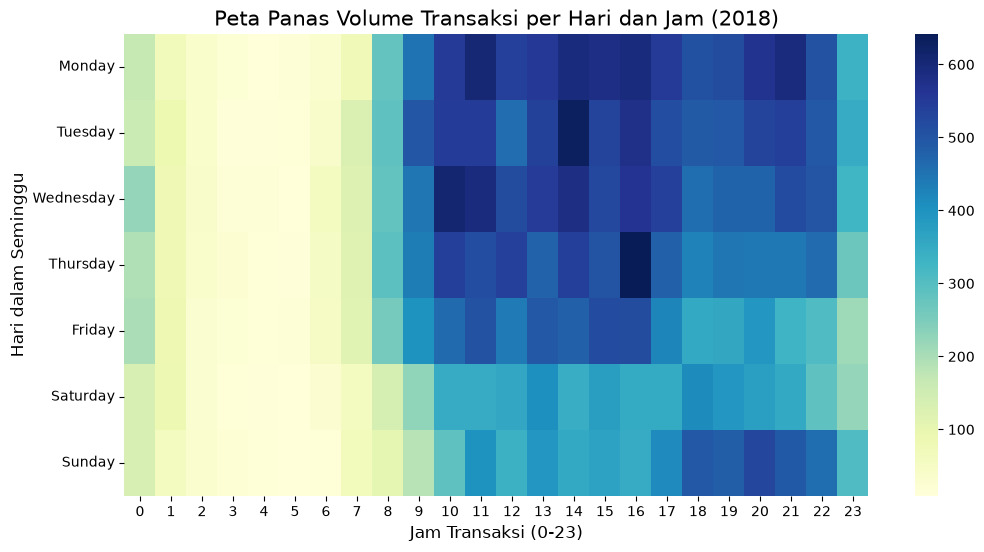

In [12]:
# Menyiapkan data: pivot table dengan baris hari dan kolom jam
heatmap_data = orders_2018.groupby(['day_of_week', 'hour']).size().unstack(fill_value=0)

# Mengurutkan hari agar berurutan dari Senin hingga Minggu
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heatmap_data = heatmap_data.reindex(days_order)

# Membuat visualisasi Heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(heatmap_data, cmap='YlGnBu', annot=False)
plt.title('Peta Panas Volume Transaksi per Hari dan Jam (2018)', fontsize=15)
plt.xlabel('Jam Transaksi (0-23)', fontsize=12)
plt.ylabel('Hari dalam Seminggu', fontsize=12)
plt.show()

### Pertanyaan 2:

C:\Users\ASUS\AppData\Local\Temp\ipykernel_19580\477310432.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='count', y='segment', data=segment_counts, palette='mako')


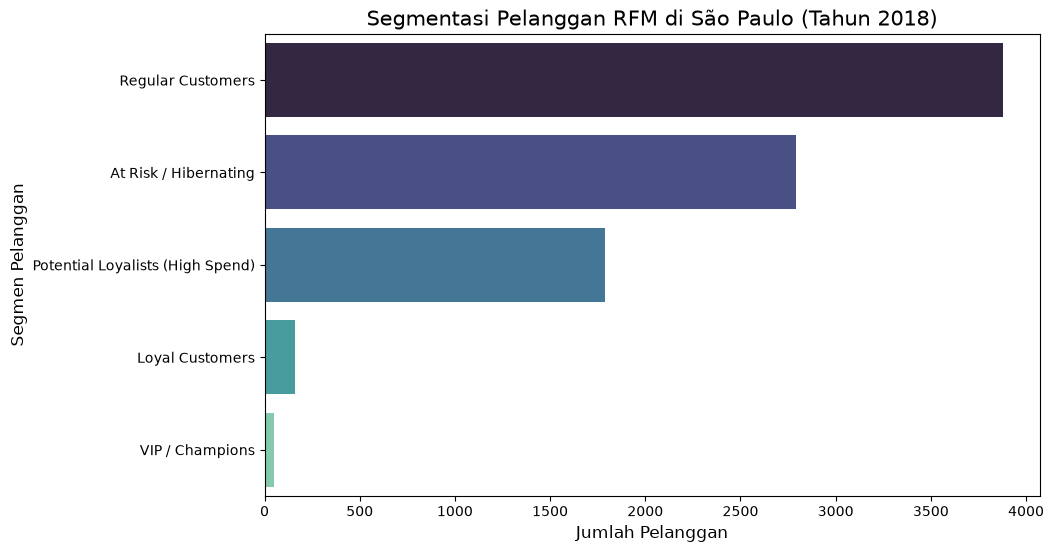

In [13]:
segment_counts = rfm_df['segment'].value_counts().reset_index()
segment_counts.columns = ['segment', 'count']

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(x='count', y='segment', data=segment_counts, palette='mako')
plt.title('Segmentasi Pelanggan RFM di São Paulo (Tahun 2018)', fontsize=15)
plt.xlabel('Jumlah Pelanggan', fontsize=12)
plt.ylabel('Segmen Pelanggan', fontsize=12)
plt.show()

**Insight:** (Opsional)
- Basis pelanggan di wilayah São Paulo sepanjang tahun 2018 sangat didominasi oleh "Regular Customers" (hampir 4.000 pelanggan) dan "At Risk / Hibernating" (sekitar 2.800 pelanggan). Fakta ini mengindikasikan tantangan besar pada retensi (churn rate tinggi), di mana mayoritas pelanggan belum menunjukkan kebiasaan berbelanja yang rutin.

- Terdapat sekitar 1.800 pelanggan dalam segmen "Potential Loyalists (High Spend)". Karena mereka baru saja berbelanja dengan nilai transaksi tinggi, kelompok ini adalah target paling potensial dan rasional untuk disasar oleh kampanye promosi agar terkonversi menjadi pelanggan setia.

- Segmen "Loyal Customers" (sekitar 200 pelanggan) dan "VIP / Champions" (kurang dari 100 pelanggan) memiliki proporsi yang sangat kecil dibandingkan total populasi. Hal ini menegaskan bahwa bisnis memerlukan perbaikan strategi retensi dan program loyalitas VIP eksklusif yang lebih agresif untuk memindahkan pelanggan dari level bawah ke level atas.

## Analisis Lanjutan (Opsional)

C:\Users\ASUS\AppData\Local\Temp\ipykernel_19580\3302295298.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='customer_state', y='customer_count', data=customer_state_counts, palette='viridis')


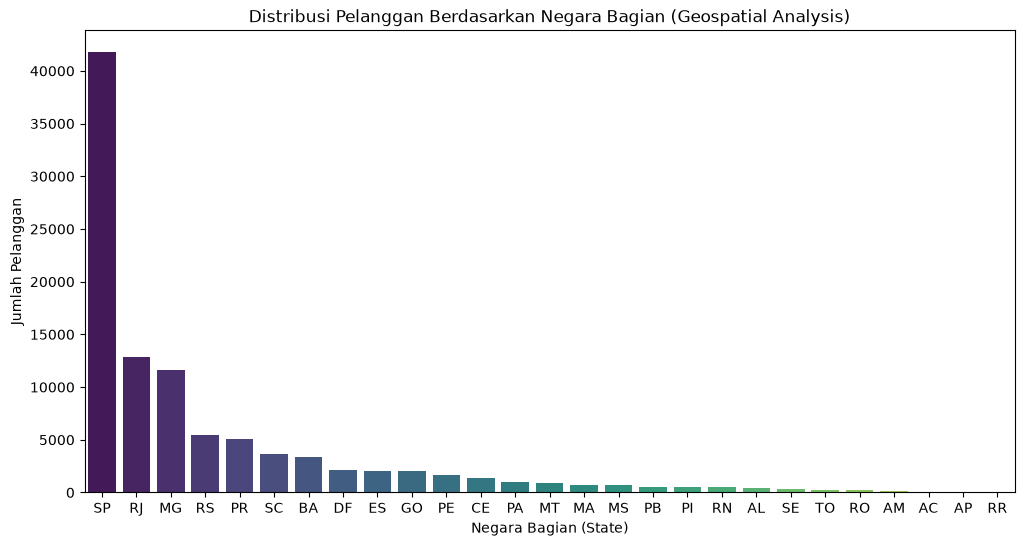

In [14]:
# Analisis Geospasial Sederhana: Distribusi Pelanggan per Negara Bagian (State)
customer_state_counts = customers_df['customer_state'].value_counts().reset_index()
customer_state_counts.columns = ['customer_state', 'customer_count']

plt.figure(figsize=(12, 6))
sns.barplot(x='customer_state', y='customer_count', data=customer_state_counts, palette='viridis')
plt.title('Distribusi Pelanggan Berdasarkan Negara Bagian (Geospatial Analysis)')
plt.xlabel('Negara Bagian (State)')
plt.ylabel('Jumlah Pelanggan')
plt.show()

**Insight:** (Opsional)
- Mayoritas pelanggan e-commerce terkonsentrasi sangat padat di wilayah "SP" (São Paulo), jauh melampaui negara bagian lainnya seperti RJ (Rio de Janeiro) dan MG (Minas Gerais). Hal ini mengonfirmasi bahwa fokus analisis RFM pada wilayah São Paulo sebelumnya adalah keputusan yang tepat karena mewakili porsi pasar terbesar.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Volume transaksi tertinggi selama tahun 2018 terjadi pada hari kerja (Senin–Jumat) antara pukul 10:00 hingga 16:00, dengan titik puncak spesifik pada hari Kamis pukul 16:00 dan Selasa pukul 14:00. Aktivitas belanja pelanggan menurun drastis pada akhir pekan (Sabtu–Minggu) dan dini hari.

- **Conclusion pertanyaan 2:** Segmentasi pelanggan di São Paulo sepanjang tahun 2018 didominasi oleh Regular Customers dan At Risk / Hibernating, yang menunjukkan bahwa mayoritas pelanggan memiliki tingkat retensi yang rendah. Meskipun segmen VIP / Champions dan Loyal Customers jumlahnya sangat kecil, terdapat sekitar 1.800 pelanggan pada segmen Potential Loyalists (High Spend). Kelompok ini memiliki riwayat belanja terbaru dengan nilai transaksi tinggi dan berpeluang besar menjadi pelanggan setia jika diberikan program retensi yang tepat.

**Rekomendasi Action Item:**
- Jadwalkan kampanye promosi, peluncuran flash sale, atau pengiriman push notification pada hari Selasa dan Kamis antara pukul 10:00 hingga 14:00 untuk memaksimalkan jangkauan saat pelanggan sedang aktif berbelanja.

- Rancang program email marketing yang dipersonalisasi berisi insentif khusus (seperti voucher diskon pembelian kedua atau gratis ongkir prioritas) yang ditargetkan langsung kepada sekitar 1.800 pelanggan di segmen Potential Loyalists guna mendorong retensi dan menaikkan status mereka menjadi VIP / Champions.

## Export Data

In [15]:
# Menggabungkan dataset untuk keperluan dashboard
all_df = orders_df.merge(customers_df, on='customer_id', how='left')
all_df = all_df.merge(order_payments_df, on='order_id', how='left')

# Menyimpan ke dalam file CSV
dirLocation = "dashboard/main_data.csv"
try:
    if os.path.isfile(dirLocation):
        print("Directory exist." + dirLocation)
    else:
        print("Directory does not exists. Creating new one." + dirLocation)
        os.makedirs(os.path.dirname(dirLocation))
except IOError:
    print("Unable to read config file and load properties.")
finally:
    all_df.to_csv("dashboard/main_data.csv", index=False)

Directory exist.dashboard/main_data.csv
